# 1. Problem

Recover conditional single-band effective absorption and reduced-scattering fields from real phase-stepped palmar imaging. The selected standard is the analytic diffusion approximation, not a neural network or Monte Carlo inverse lookup table. No independent optical-property truth exists for this hand.

In [1]:
from pathlib import Path
import sys,time,json,numpy as np,matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').is_dir():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.main import run
from src.solvers import reconstruct
from src.visualization import field_figure,residual_validity_figure,index_sensitivity_figure
import importlib.util
s=importlib.util.spec_from_file_location('standalone_judge',ROOT/'evaluation/judge.py');judge=importlib.util.module_from_spec(s);s.loader.exec_module(judge)
print(sys.executable)

D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe


# 2. Data

Independent hand and phantom three-phase frames are preserved at their native float32 precision. Known phantom reflectance is independent author calibration in float64. The central500by400ROI was fixed before fitting, followed by10by10averaging; all2000cells and fivefrequencies are retained. The acquisition band and pixel pitch are not provided. The coefficient scale derives from known cycles/mm. Refractive index1.4 is a public model convention, not a measured property.

Native frequency (cycles/mm): [0.  0.1 0.2 0.3 0.4] raw ROI: (5, 3, 500, 400) binned: (50, 40, 5)
Independent phantom reflectance: [0.61410528 0.25012484 0.1111066  0.06361206 0.04368741]


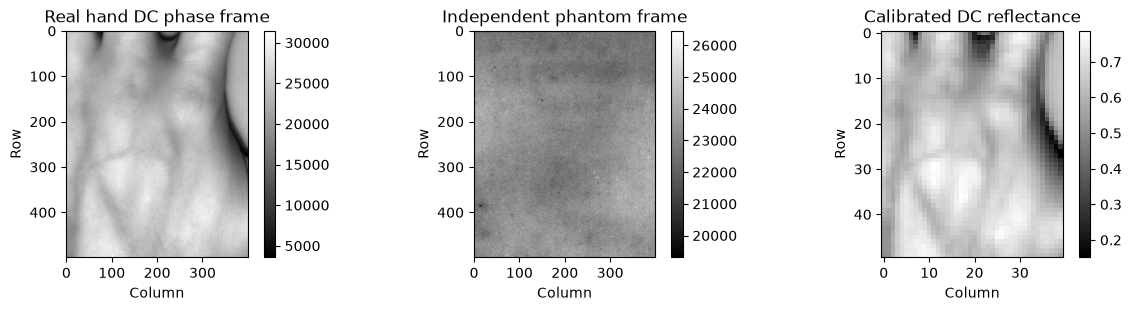

In [2]:
from src.preprocessing import load_data
hand,phantom,rcal,freq,cal,observed=load_data(ROOT/'data/raw_data.npz')
print('Native frequency (cycles/mm):',freq,'raw ROI:',hand.shape,'binned:',observed.shape)
print('Independent phantom reflectance:',rcal)
fig,ax=plt.subplots(1,3,figsize=(12,3),layout='constrained')
for a,v,title in zip(ax,[hand[0,0],phantom[0,0],observed[:,:,0]],['Real hand DC phase frame','Independent phantom frame','Calibrated DC reflectance']):
 im=a.imshow(v,cmap='gray');a.set_title(title);a.set_xlabel('Column');a.set_ylabel('Row');fig.colorbar(im,ax=a)
plt.show()

# 3. Physics

For three phase intensities, DC d=(I1+I2+I3)/3 and AC amplitude are

$$
b=\frac{\sqrt{2}}{3}\sqrt{(I_1-I_2)^2+(I_2-I_3)^2+(I_3-I_1)^2}.
$$

Calibrated reflectance equals independent phantom reflectance times hand/phantom DC ratio at zero frequency and AC ratio at nonzero frequency. The homogeneous half-space response is

$$
R(f)=\frac{3A(\mu_s'/\mu_t)}{(h+1)(h+3A)},\quad h=\sqrt{3\mu_a\mu_t+(2\pi f)^2}/\mu_t,\quad\mu_t=\mu_a+\mu_s'.
$$

Both coefficients are in inverse millimetres, f is cycles/mm, h and R are dimensionless. A=(1-r)/(2(1+r)), r=-1.440/n squared+.710/n+.668+.0636n. The relative index n=1.4 is assumed. Wavelength is not a variable in this band-specific equation; the original routine's legacy wavelength coordinate only interpolates a constant initialization table and does not describe a1nm acquisition.


# 4. Method

The next cell actively calibrates and reconstructs the complete observation. Every cell minimizes its unweighted sum of the fixed0and0.1cycles/mm squared reflectance residuals using the original classical Nelder-Mead settings, with positive final fields checked. The Judge tests every cell against a selected-low2standard residual bound and tests all predicted reflectance values. No field similarity to an arbitrary finite optimization path is required.

The two-frequency selection follows the primary paper Eq12/14: scattering dominance and fx much less than transport, with practical maximum0.25to0.33times muTransport. It is fixed from the physics, not picked to improve fit. No cells are removed. Higher3frequency observations remain available and their predicted residuals are shown explicitly as held-out diagnostics. The earlier h>=1 diagnostic must not be equated with the paper frequency threshold.

In [3]:
start=time.perf_counter()
hand,phantom,rcal,freq,cal,observed,parameters,predicted=run(ROOT)
fresh_seconds=time.perf_counter()-start
report,exit_code=judge.evaluate(ROOT/'output/reconstruction.npz');assert exit_code==0
print('Fresh complete reconstruction seconds:',fresh_seconds);print(json.dumps(report,indent=2))

Fresh complete reconstruction seconds: 1.9505869999993593
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "maximum_pixel_bound_fraction": 0.9801479474699106,
    "forward_relative_l2": 0.0
  },
  "thresholds": {
    "maximum_pixel_bound_fraction": {
      "comparison": "<=",
      "boundary": 1.0
    },
    "forward_relative_l2": {
      "comparison": "<=",
      "boundary": 1e-09
    }
  },
  "errors": []
}


# 5. Results

Source fields below were independently computed from this exact acquisition, and are a method reference rather than true optical properties. All fresh fields, predictions and sensitivity fits are computed in this notebook. A small reflectance residual does not establish accurate physiological coefficients. All five frequency-residual maps are shown without selecting favorable pixels.

Source low2-fit complete5prediction residual: 0.02828457650476184
Fresh low2-fit complete5prediction residual: 0.02828457650476184
Absorption range (1/mm): 0.0036421587541698797 0.07728191342900367
Reduced-scattering range (1/mm): 0.15390279293060033 1.9372571983796658


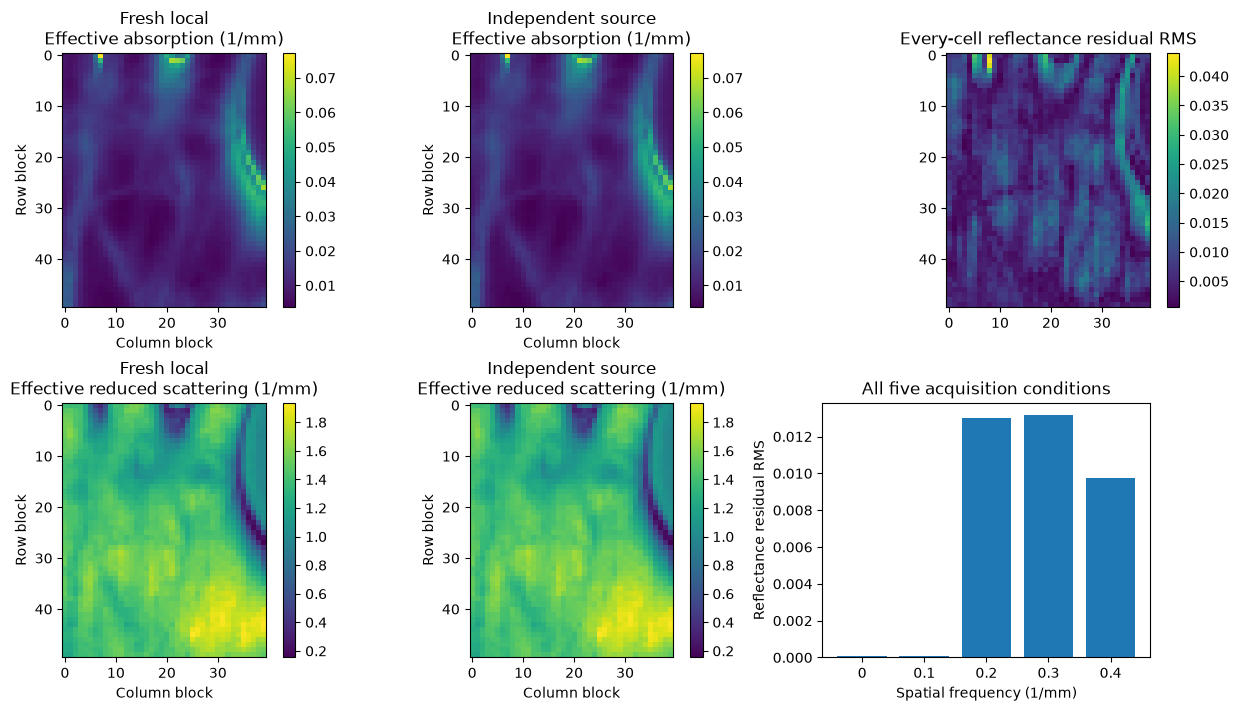

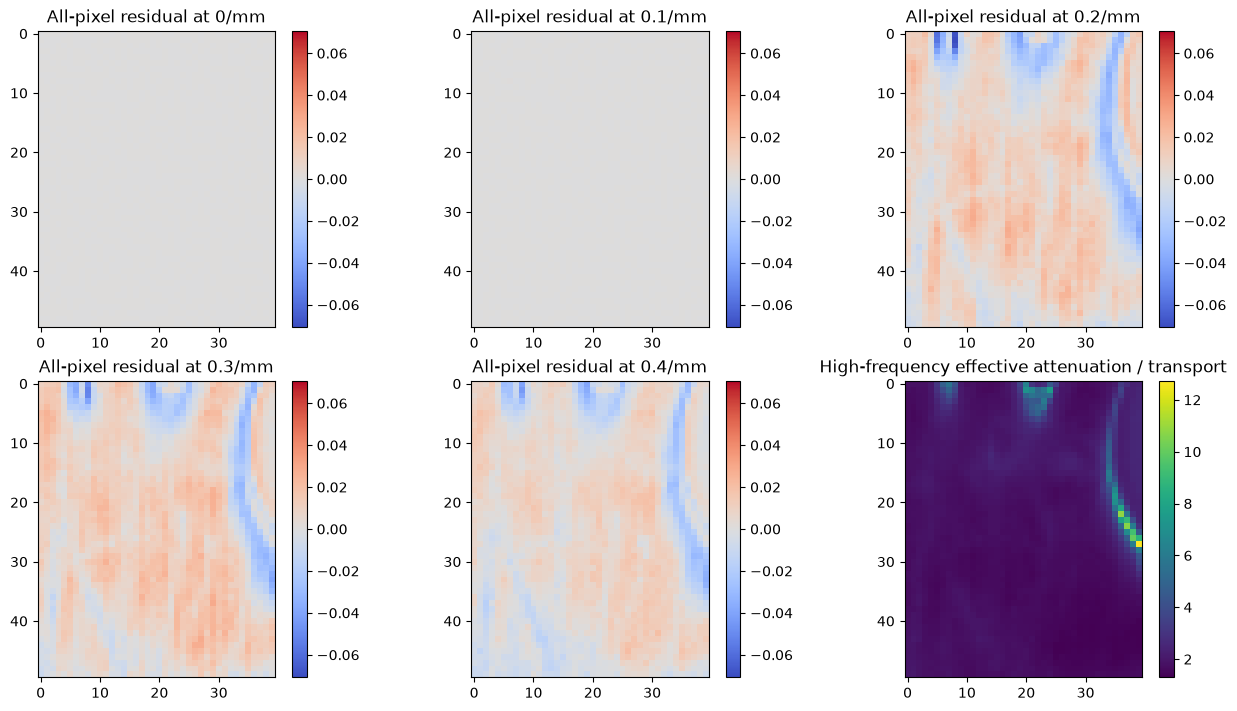

Paper frequency diagnostic: f | min(f/transport) | median | max | fraction>.25 | fraction>.33
0.0 0.0 0.0 0.0 0.0 0.0
0.1 0.05148483620330443 0.07042247728115114 0.5058128465683578 0.0085 0.0035
0.2 0.10296967240660886 0.14084495456230228 1.0116256931367156 0.049 0.028
0.3 0.15445450860991328 0.2112674318434534 1.5174385397050731 0.189 0.066
0.4 0.2059393448132177 0.28168990912460456 2.023251386273431 0.849 0.201
Scattering/absorption ratio min/median/max: 3.3644472375740535 121.39607427457693 467.9310225846689
Selected low2 fit RMS: 6.302402802713302e-05
Held-out3 prediction RMS: 0.01207537414088001
All5 comparison fresh/source relative residual: 0.02074840391294808 0.02074840391294808


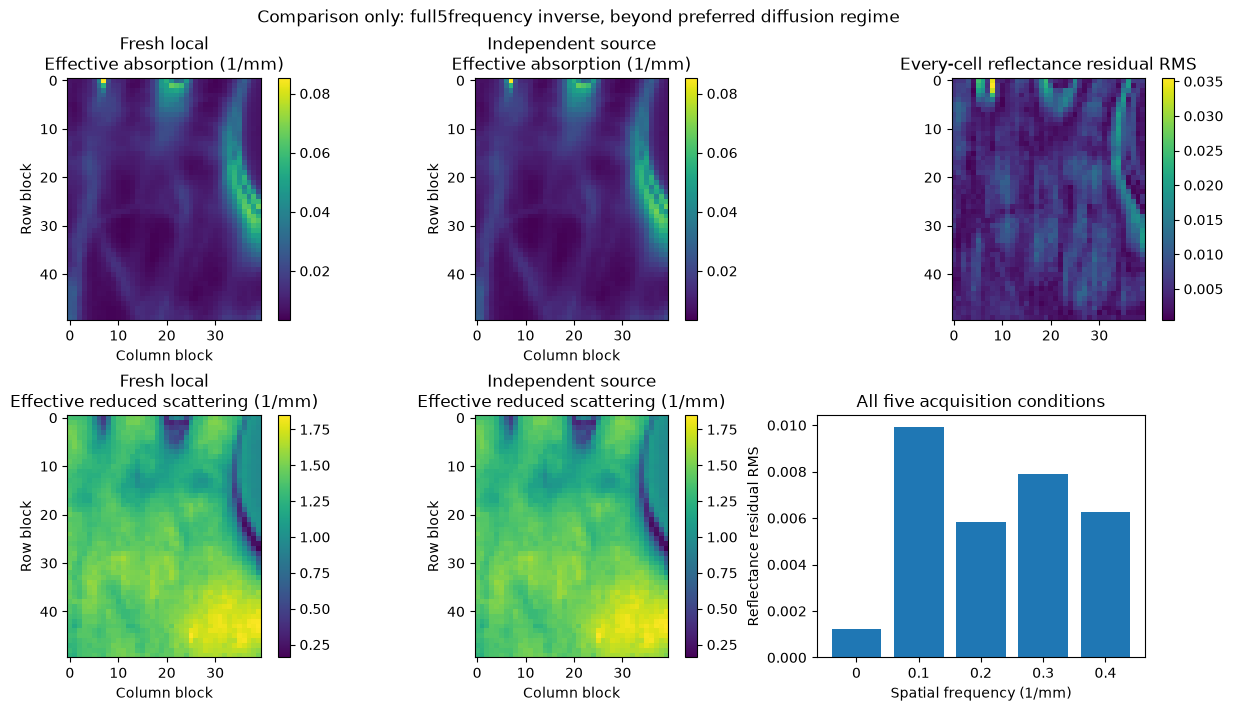

In [4]:
up=np.load(ROOT/'notebooks/reference_outputs/upstream.npz')
print('Source low2-fit complete5prediction residual:',np.linalg.norm(up['output_predicted']-up['output_binned'])/np.linalg.norm(up['output_binned']))
print('Fresh low2-fit complete5prediction residual:',np.linalg.norm(predicted-observed)/np.linalg.norm(observed))
print('Absorption range (1/mm):',parameters[:,:,0].min(),parameters[:,:,0].max())
print('Reduced-scattering range (1/mm):',parameters[:,:,1].min(),parameters[:,:,1].max())
fig=field_figure(parameters,up['output_parameters'],predicted,observed,freq);plt.show()
fig2=residual_validity_figure(parameters,predicted,observed,freq);plt.show()
transport=parameters.sum(axis=2)
print('Paper frequency diagnostic: f | min(f/transport) | median | max | fraction>.25 | fraction>.33')
for f0 in freq:
 v=f0/transport
 print(f0,v.min(),np.median(v),v.max(),np.mean(v>.25),np.mean(v>.33))
print('Scattering/absorption ratio min/median/max:',(parameters[:,:,1]/parameters[:,:,0]).min(),np.median(parameters[:,:,1]/parameters[:,:,0]),(parameters[:,:,1]/parameters[:,:,0]).max())
print('Selected low2 fit RMS:',np.sqrt(np.mean((predicted[:,:,:2]-observed[:,:,:2])**2)))
print('Held-out3 prediction RMS:',np.sqrt(np.mean((predicted[:,:,2:]-observed[:,:,2:])**2)))
five,five_prediction=reconstruct(observed,freq,frequency_indices=(0,1,2,3,4))
five_source=np.load(ROOT/'notebooks/reference_outputs/upstream_five_frequency.npz')
print('All5 comparison fresh/source relative residual:',np.linalg.norm(five_prediction-observed)/np.linalg.norm(observed),np.linalg.norm(five_source['output_predicted']-five_source['output_binned'])/np.linalg.norm(five_source['output_binned']))
fig5=field_figure(five,five_source['output_parameters'],five_prediction,observed,freq);fig5.suptitle('Comparison only: full5frequency inverse, beyond preferred diffusion regime');plt.show()


The next full inversions change only the assumed index to1.35and1.45. These are model-convention perturbations, not independently measured calibration errors. High spatial frequencies relative to the transport coefficient and low scattering weaken diffusion validity; those cells remain present in the results and evaluation.

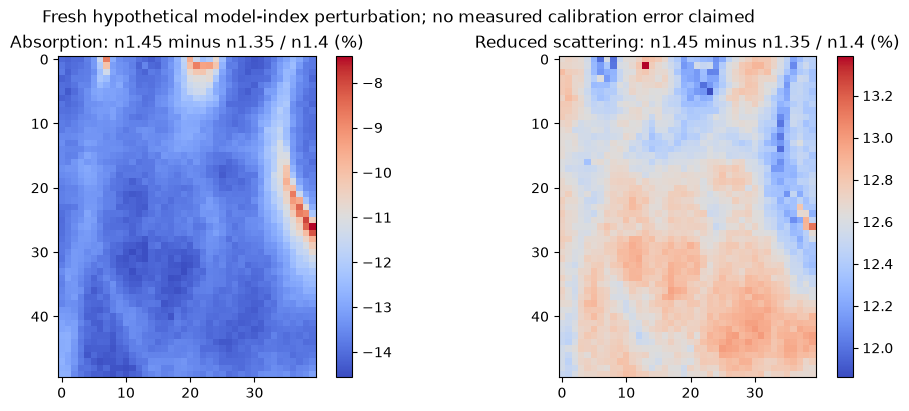

In [5]:
low,_=reconstruct(observed,freq,index=1.35)
high,_=reconstruct(observed,freq,index=1.45)
fig3=index_sensitivity_figure(parameters,low,high);plt.show()

# 6. Conclusion

The local classical inverse reproduces the independently run source standard with all five frequencies and the complete fixed ROI. Calibration is supplied independently of the hand coefficients. The fields are conditional diffusion parameters under an assumed index and half-space geometry. High-frequency transport-model error, tissue curvature/layering, unspecified spectral band and lack of independent optical truth limit physiological interpretation. Sensitivity maps show how the declared index convention affects inferred coefficients; they do not quantify an experimentally measured uncertainty.

Independent diagnostic: the diffusion formula has high-frequency asymptote R times (2 pi f) squared approaching3A muSPrime(muA+muSPrime). Thus high-frequency reflectance can increase with absorption, an approximation artifact absent from the DC monotonic check. The complete low-two-frequency fit is the selected conditional benchmark target; the5frequency inverse remains an independently computed comparison and is not an assertion that this model describes high-frequency transport accurately.